In [ ]:
import os, sys, glob, shutil, subprocess
import os.path as op
sys.path.append('.')
from utils import loadFSL, FSLeyesServer, mkdir_no_exist

import module as lmod
await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')
loadFSL()

import numpy as np
import pandas as pd
import nibabel as nib
from fsl.wrappers import fast, flirt, mcflirt, fslroi, applywarp, epi_reg
from nilearn import plotting, image
import matplotlib.pyplot as plt


In [3]:
data_root = op.abspath(op.join("..", "Data1"))
anat_path = op.join(data_root, "T1", "T1w.nii.gz")
print(op.exists(anat_path))

preproc_root = op.join(data_root, "derivatives", "preprocessed_data")
anat_out = op.join(preproc_root, "anat")
mkdir_no_exist(op.join(data_root, "derivatives"))
mkdir_no_exist(preproc_root)
mkdir_no_exist(anat_out)

fig_dir = "figures"
mkdir_no_exist(fig_dir)

mni_brain = op.expandvars("$FSLDIR/data/standard/MNI152_T1_1mm_brain.nii.gz")

True


In [4]:
%gui wx


(ipykernel_launcher.py:3419): dbind-WARNING **: 17:29:32.414: Couldn't connect to accessibility bus: Failed to connect to socket /run/user/203553994/at-spi/bus_100: No such file or directory


In [5]:
fsleyesDisplay = FSLeyesServer()
fsleyesDisplay.show()

17:29:34: Debug: Adding duplicate image handler for 'Windows bitmap file'
17:29:34: Debug: Adding duplicate animation handler for '1' type
17:29:34: Debug: Adding duplicate animation handler for '2' type
17:29:34: Debug: Adding duplicate image handler for 'Windows bitmap file'
17:29:34: Debug: Adding duplicate animation handler for '1' type
17:29:34: Debug: Adding duplicate animation handler for '2' type

(ipykernel_launcher.py:3419): Gtk-CRITICAL **: 17:29:34.940: gtk_window_resize: assertion 'width > 0' failed

(ipykernel_launcher.py:3419): Gtk-CRITICAL **: 17:29:36.640: gtk_window_resize: assertion 'width > 0' failed


In [5]:
## Skull-stripping
betted_brain = op.join(anat_out, "T1w_brain")
os.system('bet {} {} -m -R'.format(anat_path, betted_brain))

0

In [6]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(anat_path)
fsleyesDisplay.load(betted_brain + "_mask")

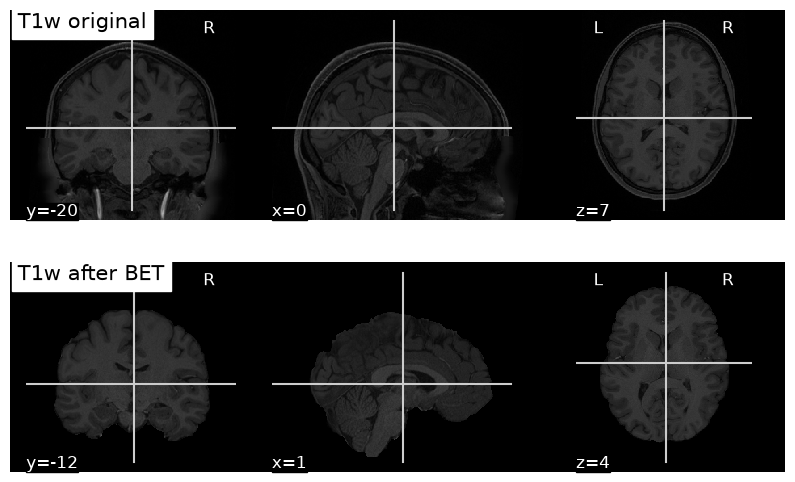

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6))
plotting.plot_anat(anat_path, title="T1w original", axes=axes[0])
plotting.plot_anat(betted_brain + ".nii.gz", title="T1w after BET", axes=axes[1])
plt.savefig(op.join(fig_dir, "1a_skullstrip.png"), dpi=200, bbox_inches="tight")

In [8]:
## Segmentation
segmentation_path = op.join(anat_out, "T1w_fast")
fast(imgs=[betted_brain], out=segmentation_path, n_classes=3)

{}

In [9]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(betted_brain)
fsleyesDisplay.load(segmentation_path + "_pve_0")
fsleyesDisplay.load(segmentation_path + "_pve_1")
fsleyesDisplay.load(segmentation_path + "_pve_2")
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[1]).cmap = 'Red'
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[2]).cmap = 'Green'
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[3]).cmap = 'Blue'

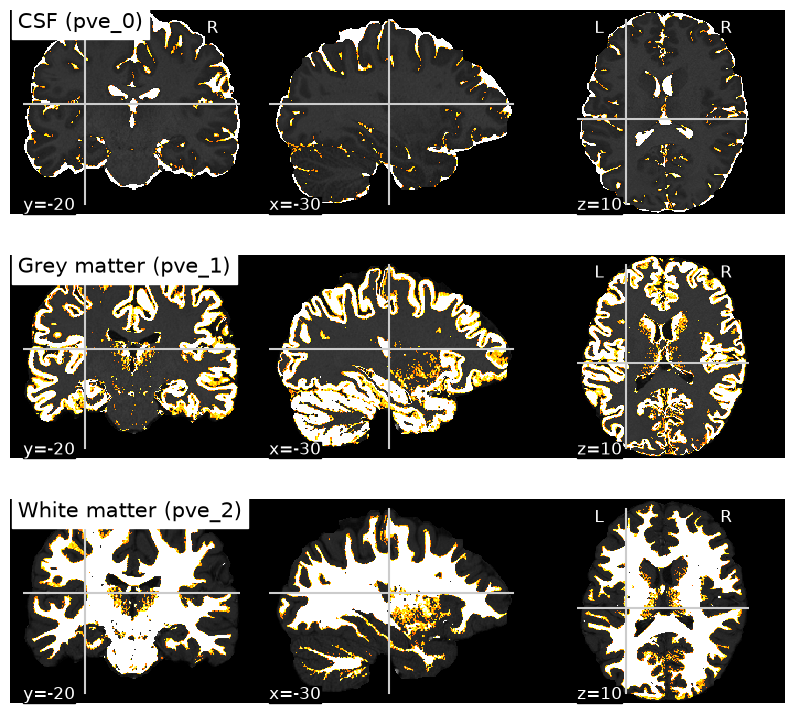

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9))
names = ["CSF (pve_0)", "Grey matter (pve_1)", "White matter (pve_2)"]
for i, name in enumerate(names):
    plotting.plot_stat_map(f"{segmentation_path}_pve_{i}.nii.gz",
                           bg_img=betted_brain + ".nii.gz",
                           title=name, cmap="hot", threshold=0.5,
                           colorbar=False, cut_coords=(-30, -20, 10),
                           axes=axes[i])
plt.savefig(op.join(fig_dir, "1b_segmentation.png"), dpi=200, bbox_inches="tight")

In [11]:
## Registration (linear)
t1_mni = op.join(anat_out, "T1w_brain_mni")
mat = op.join(anat_out, "T1w2mni.mat")
flirt(betted_brain, mni_brain, out=t1_mni, omat=mat)

{}

In [13]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(mni_brain)
fsleyesDisplay.load(t1_mni)

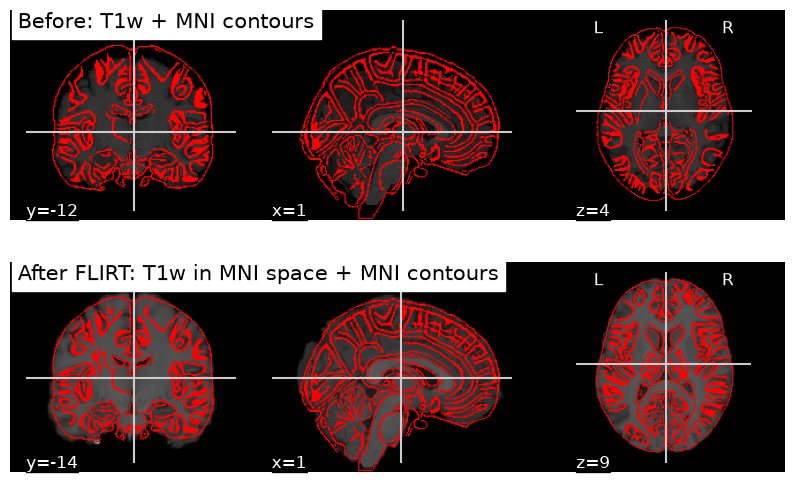

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6))
d = plotting.plot_anat(betted_brain + ".nii.gz", title="Before: T1w + MNI contours", axes=axes[0])
d.add_edges(mni_brain)
d = plotting.plot_anat(t1_mni + ".nii.gz", title="After FLIRT: T1w in MNI space + MNI contours", axes=axes[1])
d.add_edges(mni_brain)
plt.savefig(op.join(fig_dir, "1c_registration.png"), dpi=200, bbox_inches="tight")

In [13]:
## Registration (non linear)
fsl_anat_out = op.join(anat_out, "fsl_anat")
os.system('fsl_anat -i {} -o {} --clobber --nosubcortseg'.format(anat_path, fsl_anat_out))

Mon Oct 19 17:43:09 UTC 2026
Reorienting to standard orientation
Mon Oct 19 17:43:21 UTC 2026
Automatically cropping the image
Starting Single Image Segmentation
T1-weighted image
Imagesize : 260 x 311 x 221
Pixelsize : 0.7 x 0.7 x 0.7

1 6.40003
2 6.58691
3 6.80277
KMeans Iteration 0
KMeans Iteration 1
KMeans Iteration 2
KMeans Iteration 3
KMeans Iteration 4
KMeans Iteration 5
KMeans Iteration 6
KMeans Iteration 7
KMeans Iteration 8
KMeans Iteration 9
KMeans Iteration 10
KMeans Iteration 11
KMeans Iteration 12
KMeans Iteration 13
KMeans Iteration 14
Tanaka Iteration 0 bias field 10
Tanaka-inner-loop-iteration=0 MRFWeightsTotal=6.34411e+07 beta=0.02
Tanaka-inner-loop-iteration=1 MRFWeightsTotal=6.45342e+07 beta=0.02
Tanaka-inner-loop-iteration=2 MRFWeightsTotal=6.45645e+07 beta=0.02
Tanaka-inner-loop-iteration=3 MRFWeightsTotal=6.45654e+07 beta=0.02
Tanaka-inner-loop-iteration=4 MRFWeightsTotal=6.45655e+07 beta=0.02
 CLASS 1 MEAN 402.525 STDDEV 286.756 CLASS 2 MEAN 699.783 STDDEV 71.62

0

In [14]:
mni_head_2mm = op.expandvars("$FSLDIR/data/standard/MNI152_T1_2mm")

fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(mni_head_2mm)
fsleyesDisplay.load(op.join(anat_dir, "T1_to_MNI_lin"))
fsleyesDisplay.load(op.join(anat_dir, "T1_to_MNI_nonlin"))

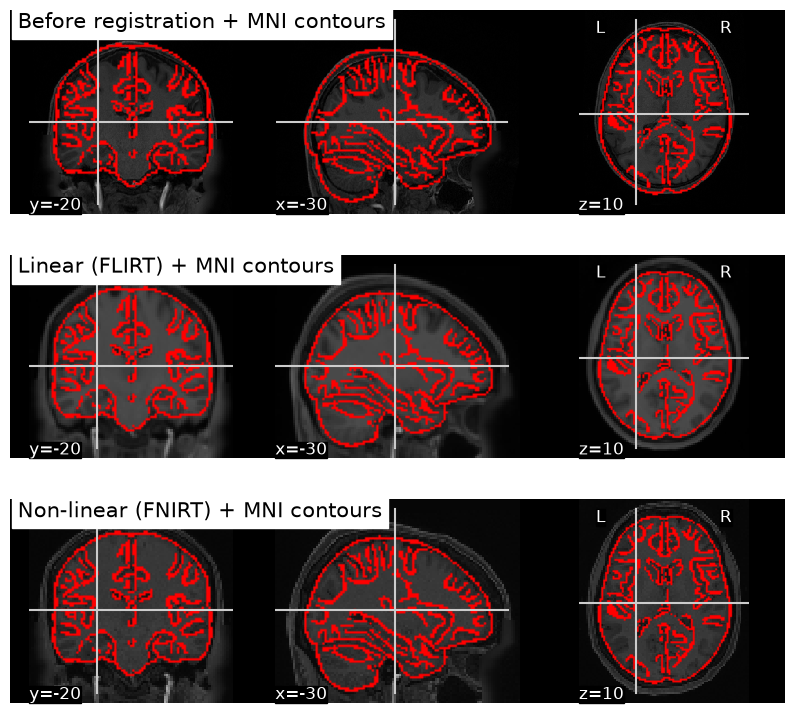

In [15]:
mni_brain_2mm = op.expandvars("$FSLDIR/data/standard/MNI152_T1_2mm_brain.nii.gz")
cuts = (-30, -20, 10)

fig, axes = plt.subplots(3, 1, figsize=(10, 9))
d = plotting.plot_anat(anat_path, title="Before registration + MNI contours",
                       cut_coords=cuts, axes=axes[0])
d.add_edges(mni_brain_2mm)
d = plotting.plot_anat(op.join(anat_dir, "T1_to_MNI_lin.nii.gz"), title="Linear (FLIRT) + MNI contours",
                       cut_coords=cuts, axes=axes[1])
d.add_edges(mni_brain_2mm)
d = plotting.plot_anat(op.join(anat_dir, "T1_to_MNI_nonlin.nii.gz"), title="Non-linear (FNIRT) + MNI contours",
                       cut_coords=cuts, axes=axes[2])
d.add_edges(mni_brain_2mm)
plt.savefig(op.join(fig_dir, "1c_registration.png"), dpi=200, bbox_inches="tight")

In [16]:
import numpy as np, pandas as pd, subprocess, nibabel as nib
from nilearn import image
from fsl.wrappers import mcflirt, fslroi, applywarp, epi_reg




func_out = op.join(preproc_root, "func")
mkdir_no_exist(func_out)





func_path = op.join(data_root, "fMRI", "tfMRI_LANGUAGE_LR", "tfMRI_LANGUAGE_LR")
moco_path = op.join(preproc_root, "func", "bold_moco")
n_vols = nib.load(func_path + ".nii.gz").shape[-1]
mid = n_vols // 2
print(n_vols, mid)


316 158


Processed data will be saved as /data/Desktop/myfiles/Data1/derivatives/preprocessed_data/func/bold_moco

McFLIRT v 2.0 - FMRI motion correction

Reading time series... 
first iteration - 8mm scaling, set tolerance
Rescaling reference volume [158] to 8 mm pixels
Registering volumes ... [159][160][161][162][163][164][165][166][167][168][169][170][171][172][173][174][175][176][177][178][179][180][181][182][183][184][185][186][187][188][189][190][191][192][193][194][195][196][197][198][199][200][201][202][203][204][205][206][207][208][209][210][211][212][213][214][215][216][217][218][219][220][221][222][223][224][225][226][227][228][229][230][231][232][233][234][235][236][237][238][239][240][241][242][243][244][245][246][247][248][249][250][251][252][253][254][255][256][257][258][259][260][261][262][263][264][265][266][267][268][269][270][271][272][273][274][275][276][277][278][279][280][281][282][283][284][285][286][287][288][289][290][291][292][293][294][295][296][297][298][299][300][30

refnum = 158
Original_refvol = -1


Registering volumes ... [159][160][161][162][163][164][165][166][167][168][169][170][171][172][173][174][175][176][177][178][179][180][181][182][183][184][185][186][187][188][189][190][191][192][193][194][195][196][197][198][199][200][201][202][203][204][205][206][207][208][209][210][211][212][213][214][215][216][217][218][219][220][221][222][223][224][225][226][227][228][229][230][231][232][233][234][235][236][237][238][239][240][241][242][243][244][245][246][247][248][249][250][251][252][253][254][255][256][257][258][259][260][261][262][263][264][265][266][267][268][269][270][271][272][273][274][275][276][277][278][279][280][281][282][283][284][285][286][287][288][289][290][291][292][293][294][295][296][297][298][299][300][301][302][303][304][305][306][307][308][309][310][311][312][313][314][315][157][156][155][154][153][152][151][150][149][148][147][146][145][144][143][142][141][140][139][138][137][136][135][134][133][132][131][130][129][128][127][126][125][124][123][122][121][120][

mot_params = (316, 6)


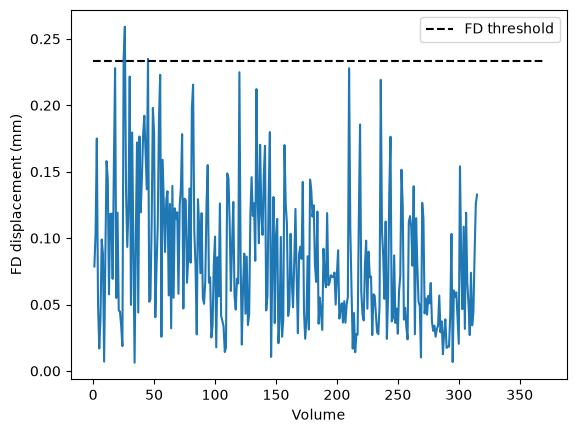

mean FD : 0.085 mm | max : 0.259 mm
Volums over the threshold : [25, 26, 45]


In [19]:
mcflirt(infile=func_path, o=moco_path, plots=True, report=True, dof=6, mats=False)


def load_mot_params_fsl_6_dof(path):
    return pd.read_csv(path, sep=r"\s+", header=None,
                       names=['Rotation x', 'Rotation y', 'Rotation z',
                              'Translation x', 'Translation y', 'Translation z'])

def compute_FD_power(mot_params):
    framewise_diff = mot_params.diff().iloc[1:]
    rot_params = framewise_diff[['Rotation x', 'Rotation y', 'Rotation z']]
    converted_rots = rot_params*50
    trans_params = framewise_diff[['Translation x', 'Translation y', 'Translation z']]
    fd = converted_rots.abs().sum(axis=1) + trans_params.abs().sum(axis=1)

    return fd

mot_params = load_mot_params_fsl_6_dof(moco_path + ".par")
print(f"mot_params = {mot_params.shape}")                

fd = compute_FD_power(mot_params).to_numpy()
threshold = np.quantile(fd,0.75) + 1.5*(np.quantile(fd,0.75) - np.quantile(fd,0.25))

plt.plot(list(range(1, fd.size+1)), fd)
plt.xlabel('Volume')
plt.ylabel('FD displacement (mm)')
plt.hlines(threshold, 0, 370,colors='black', linestyles='dashed', label='FD threshold')
plt.legend()
plt.savefig(op.join(fig_dir, "2a_FD.png"), dpi=200, bbox_inches="tight")
plt.show()

print(f"mean FD : {fd.mean():.3f} mm | max : {fd.max():.3f} mm")
print(f"Volums over the threshold : {(np.where(fd > threshold)[0] + 1).tolist()}")

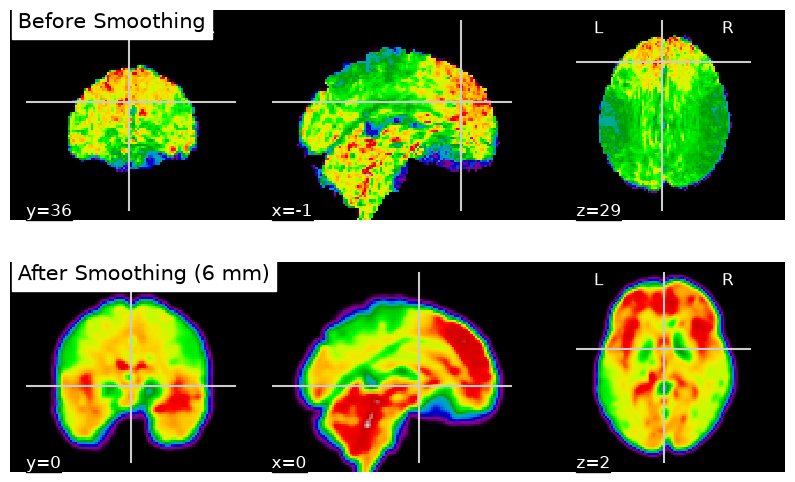

In [20]:
fwhm = 6
smooth_path = moco_path + f"_smoothed-{fwhm}mm"
subprocess.run(["fslmaths", moco_path, "-s", str(fwhm / 2.3548), smooth_path])

vol = 100   
fig, axes = plt.subplots(2, 1, figsize=(10, 6))
plotting.plot_epi(image.index_img(moco_path + ".nii.gz", vol), title="Before Smoothing", axes=axes[0])
plotting.plot_epi(image.index_img(smooth_path + ".nii.gz", vol), title=f"After Smoothing ({fwhm} mm)", axes=axes[1])
plt.savefig(op.join(fig_dir, "2b_smoothing.png"), dpi=200, bbox_inches="tight")

FLIRT pre-alignment
Running BBR
0.935369 0.999171 -0.040412 -0.004946 0.000000 0.040028 0.997274 -0.061992 0.000000 0.007437 0.061743 0.998064 0.000000 -8.489847 -1.492171 6.202232 1.000000 


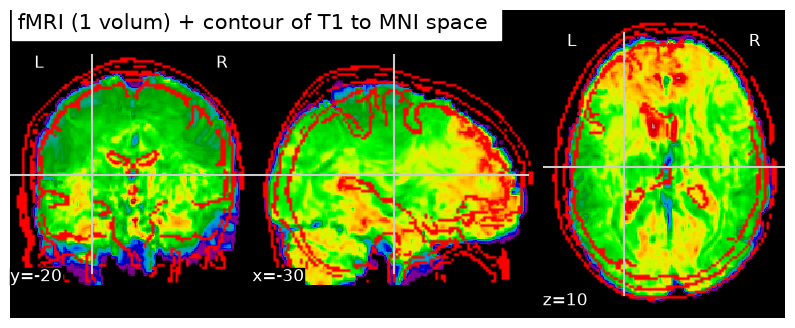

In [21]:
anat_dir = fsl_anat_out + ".anat"
t1_head  = op.join(anat_dir, "T1_biascorr")
t1_brain = op.join(anat_dir, "T1_biascorr_brain")
wm_seg   = op.join(anat_dir, "T1_fast_pve_2.nii.gz")

ref_vol = op.join(func_out, "bold_moco_midvol")
fslroi(moco_path, ref_vol, mid, 1)

epi2t1 = op.join(func_out, "epi2t1")
subprocess.run(["epi_reg", f"--epi={ref_vol}", f"--t1={t1_head}", f"--t1brain={t1_brain}",
                f"--out={epi2t1}", f"--wmseg={wm_seg}"])

epi_mni = op.join(func_out, "epi_in_MNI")
applywarp(src=ref_vol, ref=mni_brain, out=epi_mni,
          warp=op.join(anat_dir, "T1_to_MNI_nonlin_coeff"),
          premat=epi2t1 + ".mat")

t1_mni = op.join(anat_dir, "T1_to_MNI_nonlin.nii.gz")
fig, ax = plt.subplots(figsize=(10, 4))
d = plotting.plot_epi(epi_mni + ".nii.gz", cut_coords=(-30, -20, 10), axes=ax,
                      title="fMRI (1 volum) + contour of T1 to MNI space ")
d.add_edges(t1_mni)
plt.savefig(op.join(fig_dir, "2c_overlay.png"), dpi=200, bbox_inches="tight")

fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(t1_mni)
fsleyesDisplay.load(epi_mni)

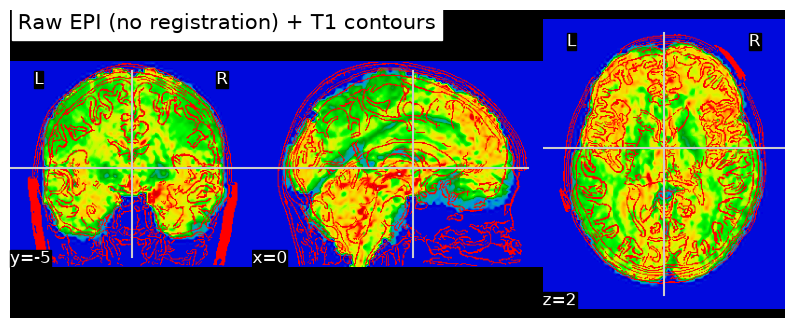

In [22]:
raw_ref = image.resample_to_img(ref_vol + ".nii.gz", t1_head + ".nii.gz")
fig, ax = plt.subplots(figsize=(10, 4))
d = plotting.plot_epi(raw_ref, axes=ax, title="Raw EPI (no registration) + T1 contours")
d.add_edges(t1_head + ".nii.gz")
plt.savefig(op.join(fig_dir, "2c_overlay_noreg.png"), dpi=200, bbox_inches="tight")